In [1]:
import warnings

import sys
import os
import gc
import numpy as np
import matplotlib.pyplot as plt

from lmfit import Model as LM_Model
from lmfit import Parameters as LM_Parameters

sys.path.append("/home/matteo/Software/nDspec/src")

from ndspec.Timing import PowerSpectrum
import ndspec.Models as models

warnings.filterwarnings(action="ignore") 

 Solar Abundance Vector set to angr:  Anders E. & Grevesse N. Geochimica et Cosmochimica Acta 53, 197 (1989)
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996


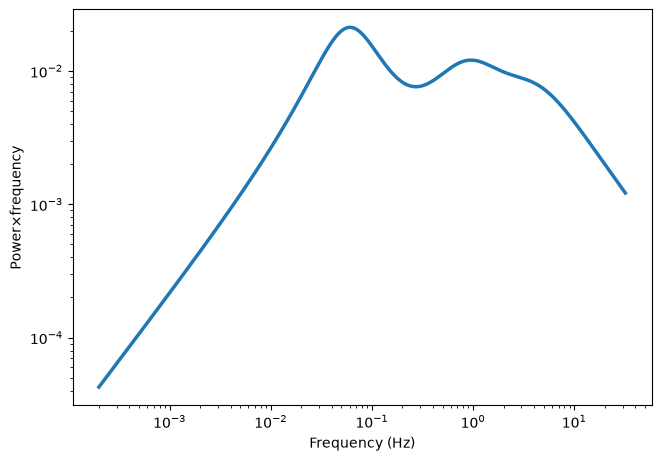

In [2]:
#Define our time grid and power spectrum object
#need to do this to get the grid of Fourier frequencies right
obs_time = 5e3
dt = 1/64
N = int(obs_time/dt)
times = np.linspace(dt,obs_time,N)

psd_model = PowerSpectrum(times)

#generate a single Lorentzian instance
def lorentz(freq,peak_f,q,rms):
    par_array = np.array([peak_f,q,rms])
    model = models.lorentz(freq,par_array)
    return model

#Define our model for the power spectrum directly in Fourier space, as a sum of
#two Lorentzians
Lorentz_model = LM_Model(lorentz, prefix="l1_") + \
                LM_Model(lorentz, prefix="l2_") + \
                LM_Model(lorentz, prefix="l3_")

Lorentz_model_parameters = LM_Parameters()
Lorentz_model_parameters.add_many(('l1_peak_f', 0.06, True, 1e-3, 0.3),
                                  ('l1_q', 0.5, True, 0, 2),
                                  ('l1_rms', 0.20, True),
                                  ('l2_peak_f', 0.9, True, 0.3, 1.25),
                                  ('l2_q', 0.3, True, 0, 2),
                                  ('l2_rms', 0.15, True),
                                  ('l3_peak_f', 4.0, True, 1.25, 10),
                                  ('l3_q', 0.2, True, 0, 2),
                                  ('l3_rms', 0.12, True),
                                 )

#Assign the model array to power_spec and plot the result
psd_model.set_psd_model(Lorentz_model,Lorentz_model_parameters)
psd_model.compute_psd()
psd_model.plot_psd()

<Axes: xlabel='Time (s)', ylabel='counts'>

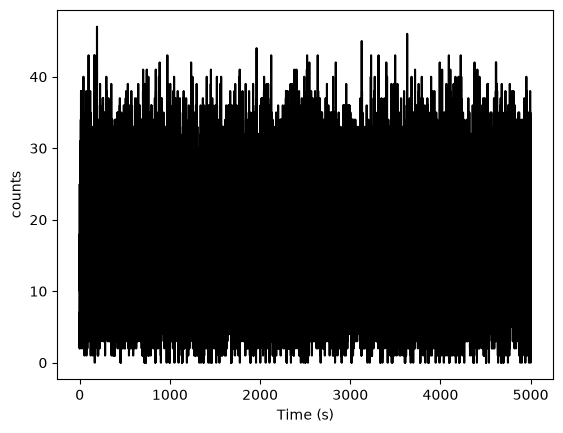

In [3]:
from ndspec.Simulator import simulate_lightcurve

countrate = 1000

simulated_observation = simulate_lightcurve(psd_model,obs_time,dt,countrate)

simulated_observation.plot()

In [4]:
from stingray import Powerspectrum,AveragedPowerspectrum

ps = Powerspectrum.from_lightcurve(simulated_observation, norm="frac")

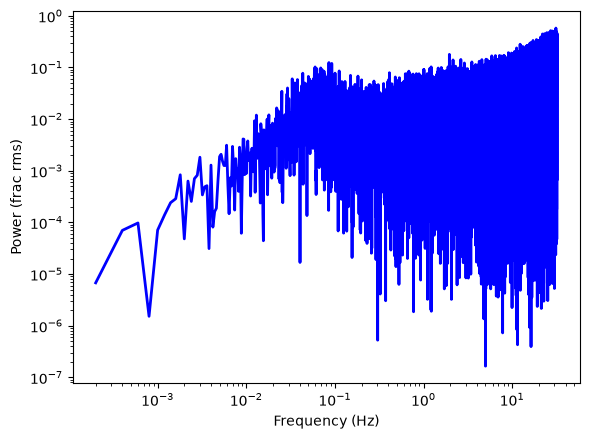

In [5]:
fig, ax1 = plt.subplots(1,1,figsize=(6,4.5))
ax1.loglog(ps.freq, ps.power*ps.freq, lw=2, color='blue')
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("Power (frac rms)")
ax1.tick_params(axis='x')
ax1.tick_params(axis='y')
ax1.tick_params(which='major',)
ax1.tick_params(which='minor')
fig.tight_layout()

9it [00:00, 1489.81it/s]


0.001999126683590697


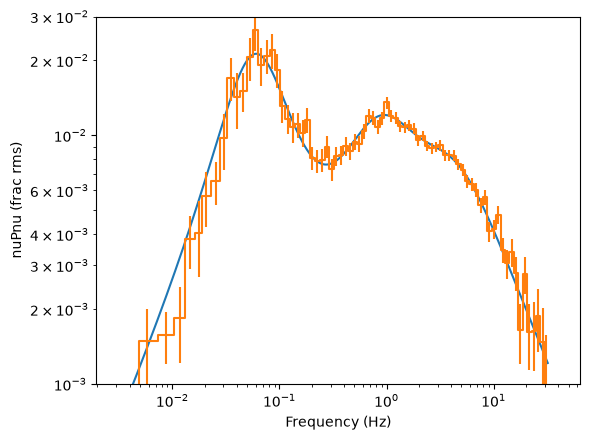

In [6]:
from stingray.fourier import poisson_level, get_average_ctrate

segment_size=512

avg_ps = AveragedPowerspectrum.from_lightcurve(simulated_observation,segment_size, norm="frac")
log_avg_ps = avg_ps.rebin_log(f=0.1)

#remove the Poisson noise
# Calculate the mean count rate
ctrate = get_average_ctrate(simulated_observation.time, simulated_observation.gti, 
                            segment_size, simulated_observation.counts)
# Calculate the Poisson noise level
noise = poisson_level("frac", meanrate=ctrate)
print(noise)

fig, ax1 = plt.subplots(1,1,figsize=(6,4.5))
ax1.loglog(psd_model.freqs,psd_model.power_spec*psd_model.freqs)
ax1.errorbar(log_avg_ps.freq, (log_avg_ps.power-noise)*log_avg_ps.freq,
             yerr=(log_avg_ps.power_err)*log_avg_ps.freq,drawstyle='steps-mid')
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("nuPnu (frac rms)")
ax1.tick_params(axis='x')
ax1.tick_params(axis='y')
ax1.tick_params(which='major',)
ax1.tick_params(which='minor')
ax1.set_xlim([1/segment_size,1/dt])
ax1.set_ylim([1e-3,3e-2])
fig.tight_layout()

Text(0, 0.5, 'rms')

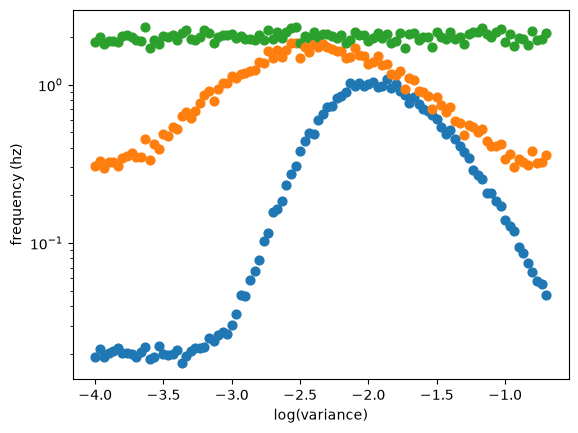

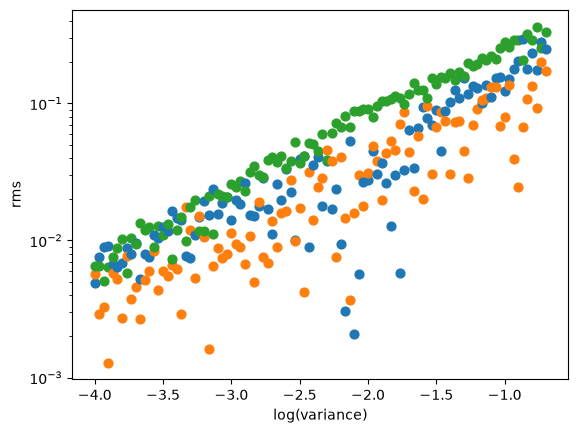

In [7]:
var_min = -4
var_max = -0.7

log_frac_var= np.linspace(var_min,var_max,100)

#shared rng generator
seed = 4269
rng = np.random.default_rng(seed)

def draw_psd_params(logvar, lo=-4, hi=-0.7):
    #convert an input variance to some interval from 0 to 1
    t = (logvar - lo)/(hi - lo)
    #now define the lorentzians; the high frequency one always peaks 
    #at around a few Hz, the intermediate one moves up and down with rms
    #the lower one is always zero centered
    nu_peak_3 = rng.normal(loc=2,scale=0.15)
    ratio     = rng.uniform(0.65, 0.7)      
    #change the factors in the sin to make the mid lorentzian rise more or less
    #quickly at a given rms. the factor inside the sin is for setting at which rms
    # the frequencies reach their maximum, the factor outside is for setting how
    #sharp the change in frequencies is with rms
    nu_peak_2 = ratio * nu_peak_3 * (0.25+np.sin(np.pi*t)**3)
    #this sets different values of nu_break before/after the peak of the hims
    t0= 0.6
    sL = 0.1
    sR = 0.15
    s = np.where(t < t0, sL, sR)
    g = np.exp(-0.5 * ((t - t0) / s)**2)
    nu_break_target = 2e-2 + 1.*g
    nu_peak_1 = rng.normal(nu_break_target,scale=0.05*nu_break_target)    
    nu_peak = np.asarray([nu_peak_1,nu_peak_2,nu_peak_3])
    #now the Q values just set to small numbers
    q_3 = rng.uniform(0,0.3)
    q_2 = rng.uniform(0,0.3)
    #q1 is some very small value so that for the first lorentzian, nu_peak = nu_break
    q_1 = rng.uniform(0,1e-2)  
    q = np.asarray([q_1,q_2,q_3])
    #finally, the normalisations so that the first lorentzian always drops before 
    #the second, which should always drop before the third 
    #the fixed number sets how much spread there is in the draws
    frac = rng.dirichlet([3-2.5*np.sin(np.pi*t**1.5)**3, 
                          1, 
                          3+2.5*np.sin(np.pi*t**1.5)**1])  
    var  = frac * 10**logvar                    
    rms  = np.sqrt(var)   
    return nu_peak, q, rms

plt.figure(1)
for logvar in log_frac_var:
    draws, _, _ = draw_psd_params(logvar)
    plt.scatter(logvar,draws[0],s=40,color="C0")
    plt.scatter(logvar,draws[1],s=40,color="C1")
    plt.scatter(logvar,draws[2],s=40,color="C2")
plt.yscale('log')
plt.xlabel("log(variance)")
plt.ylabel("frequency (hz)")

plt.figure(2)
for logvar in log_frac_var:
    _, _, draws = draw_psd_params(logvar)
    plt.scatter(logvar,draws[0],s=40,color="C0")
    plt.scatter(logvar,draws[1],s=40,color="C1")
    plt.scatter(logvar,draws[2],s=40,color="C2")
plt.yscale('log')
plt.xlabel("log(variance)")
plt.ylabel("rms")

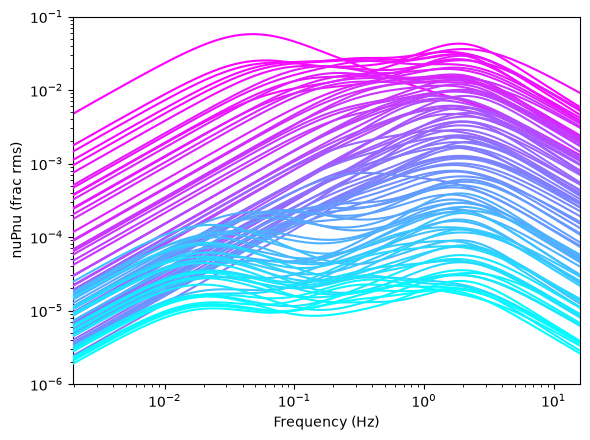

In [8]:
import matplotlib.pylab as pl
from matplotlib import cm
colorscale = pl.cm.cool(np.linspace(0.,1.,len(log_frac_var)))

fig, ax1 = plt.subplots(1,1,figsize=(6,4.5))

for index, logvar in enumerate(log_frac_var):
    peak_vals, q_vals, rms_vals = draw_psd_params(logvar,var_min,var_max)
    #do this in ndspec so it looks a bit better ig 
    for key in Lorentz_model_parameters.keys():
        for i in range(0,3):
            if "peak_f" in key:            
                comp_name = "l"+str(i+1)+"_peak_f"
                Lorentz_model_parameters[comp_name].value=peak_vals[i]
            if "q" in key:
                comp_name = "l"+str(i+1)+"_q"
                Lorentz_model_parameters[comp_name].value=q_vals[i]
            if "rms" in key:
                comp_name = "l"+str(i+1)+"_rms"
                Lorentz_model_parameters[comp_name].value=rms_vals[i]
    modelvals = Lorentz_model.eval(Lorentz_model_parameters,freq=psd_model.freqs)
    
    ax1.loglog(psd_model.freqs,modelvals*psd_model.freqs,color=colorscale[index],zorder=101-index)

ax1.set_xlim([1/segment_size,0.25/dt])
ax1.set_ylim([1e-6,1e-1])
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("nuPnu (frac rms)")
fig.tight_layout()

In [9]:
def generate_data_psd(logvar,countrate,exposure,dt=1/128,segsize=512,var_min=-4,var_max=-0.7):
    N = int(exposure/dt)
    times = np.linspace(dt,exposure,N)    
    psd_model = PowerSpectrum(times)
    peak_vals, q_vals, rms_vals = draw_psd_params(logvar,var_min,var_max)
    for key in Lorentz_model_parameters.keys():
        for i in range(0,3):
            if "peak_f" in key:            
                comp_name = "l"+str(i+1)+"_peak_f"
                Lorentz_model_parameters[comp_name].value=peak_vals[i]
            if "q" in key:
                comp_name = "l"+str(i+1)+"_q"
                Lorentz_model_parameters[comp_name].value=q_vals[i]
            if "rms" in key:
                comp_name = "l"+str(i+1)+"_rms"
                Lorentz_model_parameters[comp_name].value=rms_vals[i]
    psd_model.set_psd_model(Lorentz_model,Lorentz_model_parameters)
    psd_model.compute_psd()
    simulated_observation = simulate_lightcurve(psd_model,exposure,dt,countrate)
    avg_ps = AveragedPowerspectrum.from_lightcurve(simulated_observation,segsize, norm="frac",silent=True)
    log_avg_ps = avg_ps.rebin_log(f=0.1)
    model_vals = psd_model.compute_psd(freq=log_avg_ps.freq)
    #track the Poisson noise
    # Calculate the mean count rate
    ctrate = get_average_ctrate(simulated_observation.time, simulated_observation.gti, 
                                segsize, simulated_observation.counts)
    # Calculate the Poisson noise level
    noise = poisson_level("frac", meanrate=ctrate)

    return dict(freq=log_avg_ps.freq, power=log_avg_ps.power - noise, err=log_avg_ps.power_err,
                noise=noise, logvar=logvar, peak=peak_vals, q=q_vals, rms=rms_vals,
                countrate=countrate, exposure=exposure, model=psd_model.power_spec)

#generate some random data and track the noise
sim_data = generate_data_psd(log_frac_var[np.random.randint(0,100)],rng.uniform(5e2,1e4),rng.uniform(512,2e4))

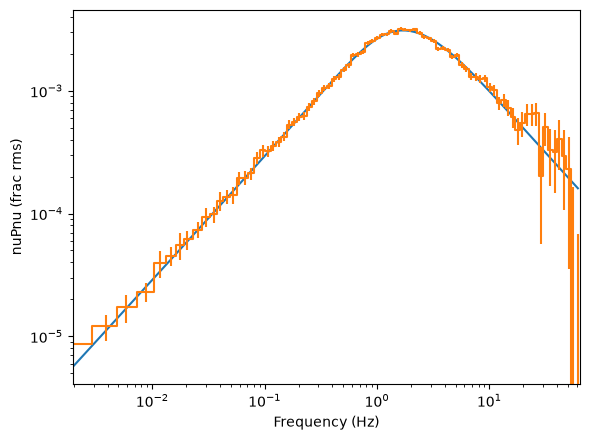

In [10]:
freqs = sim_data["freq"]
data = sim_data["power"]
data_err = sim_data["err"]
model = sim_data["model"]

fig, ax1 = plt.subplots(1,1,figsize=(6,4.5))
ax1.loglog(freqs,model*freqs)
ax1.errorbar(freqs, data*freqs,yerr=data_err*freqs,drawstyle='steps-mid')
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("nuPnu (frac rms)")
ax1.tick_params(axis='x')
ax1.tick_params(axis='y')
ax1.tick_params(which='major',)
ax1.tick_params(which='minor')
ax1.set_xlim([1/segment_size,1/dt])
#ax1.set_ylim([1e-3,3e-2])
fig.tight_layout()

In [11]:
#functions to store and load data
import h5py, json

#save data built in one batch
def save_dataset(samples, path, config):
    freq = samples[0]["freq"]
    assert all(np.allclose(s["freq"], freq) for s in samples)
    with h5py.File(path, "w") as f:
        f.create_dataset("freq", data=freq)
        for key in ["power", "err", "model", "peak", "q", "rms"]:          # (n, nbins) or (n, 3) where n is the size of the generated data
            f.create_dataset(key, data=np.stack([s[key] for s in samples]).astype(np.float32),
                             compression="gzip")
        for key in ["noise", "logvar", "countrate", "exposure"]:       # (n,)
            f.create_dataset(key, data=np.array([s[key] for s in samples]))
        f.attrs["config"] = json.dumps(config)      # attrs can't hold dicts, so JSON string


#these are for doing it in batches
def init_dataset(path, freq, nbins, config):
    with h5py.File(path, "w") as f:
        f.create_dataset("freq", data=freq)
        for key, width in [("power", nbins), ("err", nbins), ("model", nbins), ("peak",3), ("q", 3), ("rms", 3)]:
            f.create_dataset(key, shape=(0, width), maxshape=(None, width),
                             chunks=(256, width), dtype=np.float32, compression="gzip")
        for key in ["noise", "logvar", "countrate", "exposure"]:
            f.create_dataset(key, shape=(0,), maxshape=(None,), chunks=(256,), dtype=np.float64)
        f.attrs["config"] = json.dumps(config)

def append_batch(path, batch):
    n_new = len(batch)
    with h5py.File(path, "a") as f:
        n_old = f["power"].shape[0]
        for key in ["power", "err", "model", "peak", "q", "rms"]:
            f[key].resize(n_old + n_new, axis=0)
            f[key][n_old:] = np.stack([s[key] for s in batch])
        for key in ["noise", "logvar", "countrate", "exposure"]:
            f[key].resize(n_old + n_new, axis=0)
            f[key][n_old:] = [s[key] for s in batch]

def load_dataset(path):
    with h5py.File(path, "r") as f:
        d = {k: f[k][:] for k in f}
        d["config"] = json.loads(f.attrs["config"])
    return d

In [12]:
from stingray.utils import show_progress

#finally, generate and save the data
save_data = True
use_batches = True
n_samples = 10000
var_min = np.log10(6.3e-4)
var_max = np.log10(0.2)
rate_min = np.log10(1e2)
rate_max = np.log10(1e4)
seg_min = 1
seg_max = 41
dt = 1/128
segsize=512
name = "only_broadband_1e4"

if save_data is True:
    if use_batches is False:
        samples = []
        for i in show_progress(range(n_samples)):
            logvar = rng.uniform(var_min, var_max)
            countrate = 10**rng.uniform(rate_min, rate_max)
            exposure = rng.integers(seg_min, seg_max) * segsize
            samples.append(generate_data_psd(logvar, countrate, exposure,var_min=var_min,var_max=var_max))
        
        config = dict(lo=10**var_min, hi=10**var_max, dt=dt, segsize=segsize, rebin_log_factor=0.1,
                      countrate_range=[10**rate_min, 10**rate_max], nseg_range=[seg_min, seg_max], generator=name)
        save_dataset(samples, f"data/psd_dataset_{name}.h5", config)
    else:
        batch = []
        for i in show_progress(range(n_samples)):
            logvar = rng.uniform(var_min, var_max)
            countrate = 10**rng.uniform(rate_min, rate_max)
            exposure = rng.integers(seg_min, seg_max) * segsize
            batch.append(generate_data_psd(logvar, countrate, exposure,var_min=var_min,var_max=var_max))
            config = dict(lo=10**var_min, hi=10**var_max, dt=dt, segsize=segsize, rebin_log_factor=0.1,
                          countrate_range=[10**rate_min, 10**rate_max], nseg_range=[seg_min, seg_max], generator=name)
            #generate 100 samples, then check if they are the first 100 and if yes set up the file to save to
            if len(batch) == 100:
                if i + 1 == 100:                      
                    init_dataset(f"data/psd_dataset_{name}.h5", batch[0]["freq"], len(batch[0]["freq"]), config)
                #save batch to file and start over 
                append_batch(f"data/psd_dataset_{name}.h5", batch)
                batch = []
        if batch:
            append_batch(f"data/psd_dataset_{name}.h5", batch)

d = load_dataset(f"data/psd_dataset_{name}.h5")
X = d["power"]                                  
y = np.where(d["logvar"] > -1.5, 0, np.where(d["logvar"] < -2.5, 1, -1))  

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [1:37:58<00:00,  1.70it/s]


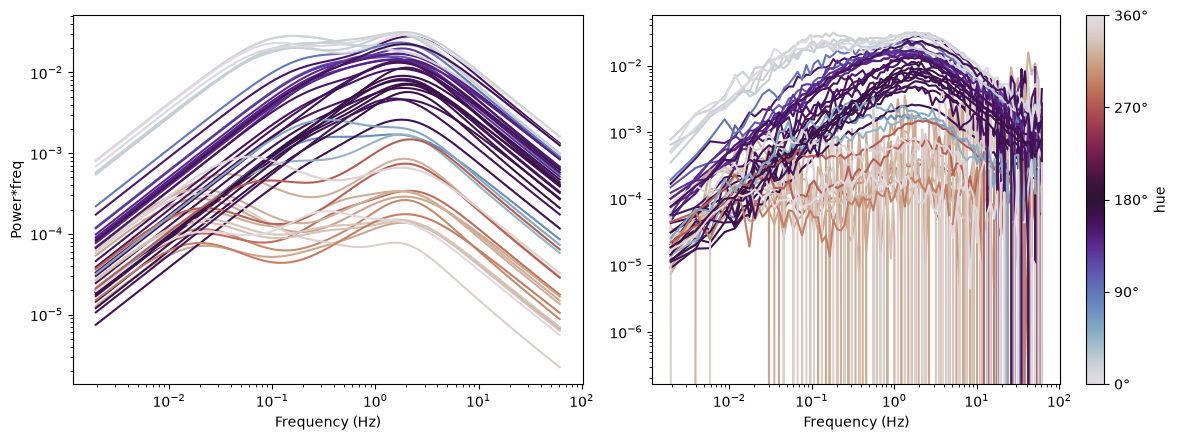

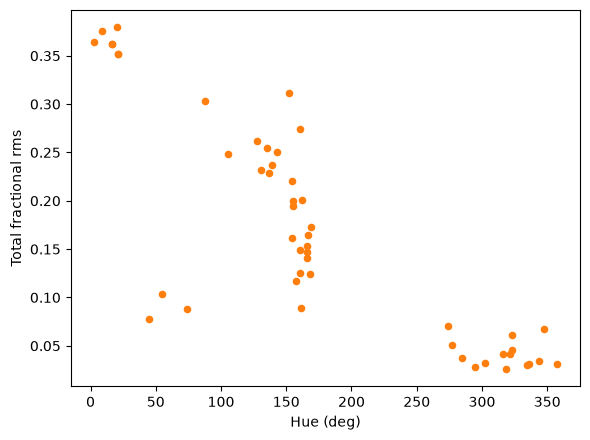

In [13]:
import matplotlib as mpl

#now to include QPOs; first we need to calculate the hue from a given model 
hue_bands = [1/256,1/16,1/4,2,16]

def get_hue(freq_array,psd_array):
    integrated_powers = []
    for index, freq in enumerate(hue_bands[:-1]):
        freq_range = np.where(np.logical_and(freq_array>=freq,freq_array<=hue_bands[index+1]))
        power = np.trapezoid(psd_array[freq_range],freq_array[freq_range])
        integrated_powers = np.append(integrated_powers,power)
    pc1 = integrated_powers[2]/integrated_powers[0]
    pc2 = integrated_powers[1]/integrated_powers[3]
    c1 = np.log10(4.5192)
    c2 = np.log10(0.453724)
    #wrap around 2pi
    hue = 0.75*np.pi-np.arctan2(np.log10(pc2)-c2,np.log10(pc1)-c1)
    return np.degrees(hue) % (360)

#sample random instances
idx = rng.choice(len(d["model"]), size=50) 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
cmap = mpl.colormaps["twilight"]
norm = mpl.colors.Normalize(vmin=0, vmax=360)

for k in idx:#range(n_samples):
    model = d["model"][k]
    data = d["power"][k]
    freqs = d["freq"]
    hue = get_hue(freqs,model)
    ax1.loglog(freqs,model*freqs,color=cmap(norm(hue)) )
    ax2.loglog(freqs,data*freqs,color=cmap(norm(hue)) )

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax2)
cb.set_ticks([0, 90, 180, 270, 360])
cb.set_ticklabels(["0°", "90°", "180°", "270°", "360°"])
cb.set_label("hue")
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("Power*freq")

ax2.set_xlabel("Frequency (Hz)")
fig.tight_layout()

#hue vs rms plot to compare with Heil/Uttley
#as long as it is remotely reasonable it is fine
fig, ax1 = plt.subplots(1,1, figsize=(6,4.5))
for k in idx:#range(n_samples):
    model = d["model"][k]
    freqs = d["freq"]
    var = np.sqrt(10**d["logvar"][k])
    hue = get_hue(freqs,model)  
    ax1.scatter(hue,var,marker="o",s=20,color="C1")

ax1.set_xlabel("Hue (deg)")
ax1.set_ylabel("Total fractional rms")
fig.tight_layout()